# Robot Learning
## Exercise 3

2025
TAs: Andrea Protopapa (andrea.protopapa@polito.it), Davide Buoso (davide.buoso@polito.it)

# 1. Introduction
This exercise will ask the student to focus on policy gradient reinforcement learning algorithms, specifically implementing the naïve REINFORCE algorithm and then exploring more advanced Actor Critic methods like Proximal Policy Optimization (PPO) and Soft Actor Critic (SAC), also leveraging on the use of well-known libraries such as Stable-Baselines3.

To proceed with the assignment, clone the starting code from the repository at the dedicated webpage and follow the steps listed below in this document.

The deadline to submit the report and code through the Github Classroom is **December 12th, at 23:59**.

# 2. Preliminaries

This assignment asks for the implementation of different policy gradient algorithms. A good preliminary knowledge of the theoretical aspects behind policy gradient and actor critic methods is highly suggested before dealing with the assignment.

In particular, make sure you revise the course slides of Lecture 6, and Chapter 13 of [1].



# 3. REINFORCE
REINFORCE is a policy optimization algorithm that directly adjusts the parameters of a stochastic policy to maximize expected cumulative rewards and it operates through gradient ascent as optimization algorithm, iteratively searching for optimal parameters that maximize the objective function.

In this section, we will implement this policy gradient algorithm for the Cartpole environment comparing it with and without a constant baseline. We will use a modified version of the CartPole environment implemented in *cp_cont.py* —the standard CartPole uses discrete actions (applying force of either -10 or 10), while in this version it takes actions in the form of a single real number, which represents an arbitrary force value.


## Task 3.1: Policy gradient with and without baseline
Implement policy gradient for the CartPole environment with continuous action space. Use agent.py for implementing the reinforcement learning algorithm itself (for example, the agent and policy classes). These classes are used to implement the main training loop in the cartpole.py file, similarly to how it was done in Exercise 1.

Use constant variance $\sigma^2 = 5$ for the output action distribution throughout the training.

Implement the following algorithms:
1. basic REINFORCE without baseline,
2. REINFORCE with a constant baseline ,
3. REINFORCE with discounted rewards normalized to zero mean and unit variance,

and compare their results.

**Hint:** The agent.py file from the first exercise session contains some useful code, which you can use as a reference.

**Hint:** Your policy should output a probability distribution over actions. A good (and easy) choice would be to use a normal distribution (from torch.distributions import Normal). Log-probabilities can be calculated using the log_prob function of the distribution.

**Hint:** If you want to understand in detail how to implement the optimization and training of a neural network in Pytorch, you can read the official documentation.

### Question 1.1
How would you choose a good value for the baseline? **Justify your answer.**

#### Answer 1.1:  A good baseline should be a representative estimate of the expected return ($V^\pi(s)$).  The goal is to make the baseline close to the actual returns so that the update only cares if a specific trajectory was better or worse than average.

### Question 1.2
How does the baseline affect the training, and **why?**

#### Answer 1.2: The baseline reduces variance in the gradient estimate without introducing bias. Because the REINFORCE gradient is proportional to the magnitude of the return, large returns cause massive updates. Subtracting a baseline centers the updates, leading to more stable and faster convergence.

## Task 3.2: Real-world control problems


### Question 2.1
What could go wrong when a model with an unbounded continuous action space and a reward function like the one used here (+1 for survival) were to be used with a physical system?

#### Answer 2.1: In a physical system, unbounded actions can lead to actuator saturation or mechanical damage.

### Question 2.2
How could the problems appearing in Question 2.1 be mitigated without putting a hard limit on the actions? **Explain your answer.**

#### Answer 2.2: You can add a penalty term to the reward function . This encourages the agent to find energy-efficient solutions and keep actions small naturally through the optimization process.

## Task 3.3: Discrete action space


### Question 3
Can policy gradient methods be used with discrete action spaces? Why/why not? Which steps of the algorithm would be problematic to perform, if any? **Explain your answer.**

#### Answer 3: Yes, policy gradient works perfectly with discrete spaces. Instead of a Normal distribution, you use a Categorical (Softmax) distribution. The only difference is how the log-probabilities are calculated

# 4. Actor-Critic Methods
Actor-Critic methods combine the advantages of value-based and policy-based reinforcement learning. In this section, we will explore two popular Actor-Critic algorithms: PPO (Proximal Policy Optimization) [2] and SAC (Soft Actor-Critic) [3].

Stable-Baselines 3 is a state-of-the-art RL library offering efficient and stable implementations of various algorithms. Specifically, it provides robust implementations for PPO and SAC, making it an ideal choice for experimentation due to its ease of use and reliability.


## Task 4
Following the [official documentation of Stable-Baselines 3](https://stable-baselines3.readthedocs.io/en/master/#), implement inside cartpole_sb3.py  the code for training and testing a policy on the continuous CartPole environment using either PPO or SAC.

### Question 4
Analyze the performance of the trained policies in terms of reward and time consumption. Additionally, compare the results with the REINFORCE algorithm you have previously obtained, highlighting any notable differences in terms of learning stability and convergence speed. **Motivate with some hypotheses** all the results obtained.

**Hint:** For the evaluation phase, refer to the "Evaluation Helper" in the documentation.

**Hint:** Feel free to adjust any hyperparameter such as learning rate or others as presented in the documentation if needed.

**Hint:** You can use callbacks for additional functionality, i.e., saving checkpoints, implementing early stopping, or integrating with TensorBoard or WandB for visualization.

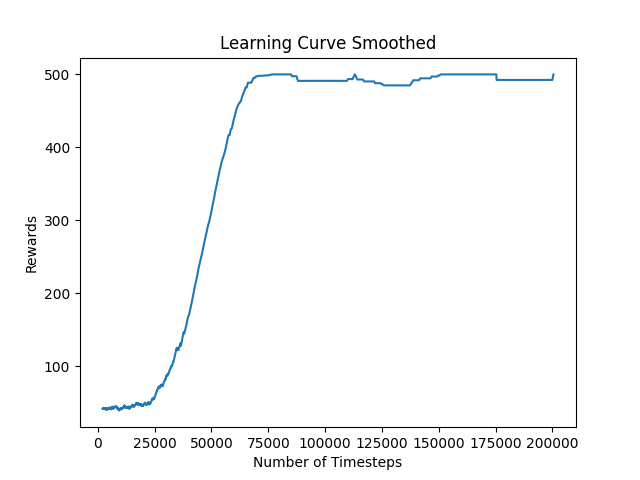

It is observed that the reward curve is rising steadily and relatively smoothly, saturating near (500) within the first 60,000 timesteps. This demonstrates high sample efficiency.

Compared to REINFORCE, PPO achieves the optimal policy with far fewer episodes. REINFORCE typically requires a very large number of samples because it discards trajectories immediately after one update

# References

**[1]** “Reinforcement Learning: An introduction (Second Edition)” by Richard S. Sutton and Andrew G. Barto, [PDF](http://incompleteideas.net/book/RLbook2020.pdf)

**[2]** Schulman, J., Wolski, F., Dhariwal, P., Radford, A., & Klimov, O. (2017). Proximal policy optimization algorithms.

**[3]** Haarnoja, T., Zhou, A., Abbeel, P., & Levine, S. (2018, July). Soft actor-critic: Off-policy maximum entropy deep reinforcement learning with a stochastic actor.